# Email / SMS Spam Detection (UCI SMS Spam Collection)

Spam classification on short message text. I picked the UCI SMS Spam Collection because it's small, public, and the labels are already cleaned, which means I could focus on the TF-IDF + Naive Bayes baseline instead of fighting the data. About 5.5k labelled messages, roughly 13% spam.

The plan was: TF-IDF on the message text, then multinomial Naive Bayes, then look at where it screws up. Spoiler — most of the errors are short messages where the model just doesn't have enough signal.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score
)
import seaborn as sns

np.random.seed(42)

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/email_spam")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Auto-download the UCI SMS Spam Collection on first run.
import urllib.request, zipfile, io
csv_path = DATA_DIR / "SMSSpamCollection"
if not csv_path.exists():
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    print(f"downloading from {url}")
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
        z.extractall(DATA_DIR)
    print("done ->", list(DATA_DIR.iterdir()))


downloading from https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip


done -> [PosixPath('../../data/email_spam/readme'), PosixPath('../../data/email_spam/SMSSpamCollection'), PosixPath('../../data/email_spam/README.txt')]


## Load

In [2]:
# Try the common filenames. The UCI file is tab-separated with no header.
candidates = ["SMSSpamCollection", "SMSSpamCollection.txt", "spam.csv", "emails.csv"]
df = None
for fname in candidates:
    p = DATA_DIR / fname
    if p.exists():
        if fname.endswith(".csv"):
            df = pd.read_csv(p, encoding="latin-1")
            # the kaggle mirror has weird unnamed columns
            df = df[[c for c in df.columns if not c.startswith("Unnamed")]]
            df.columns = ["label", "message"][:len(df.columns)]
        else:
            df = pd.read_csv(p, sep="\t", names=["label", "message"], encoding="latin-1")
        break
if df is None:
    raise FileNotFoundError(f"No spam file in {DATA_DIR}. See README.")

df["label"] = (df["label"].str.lower() == "spam").astype(int)
print(df.shape, "  positive rate:", round(df["label"].mean(), 3))
df.head()


(5572, 2)   positive rate: 0.134


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## eda — just enough to sanity check

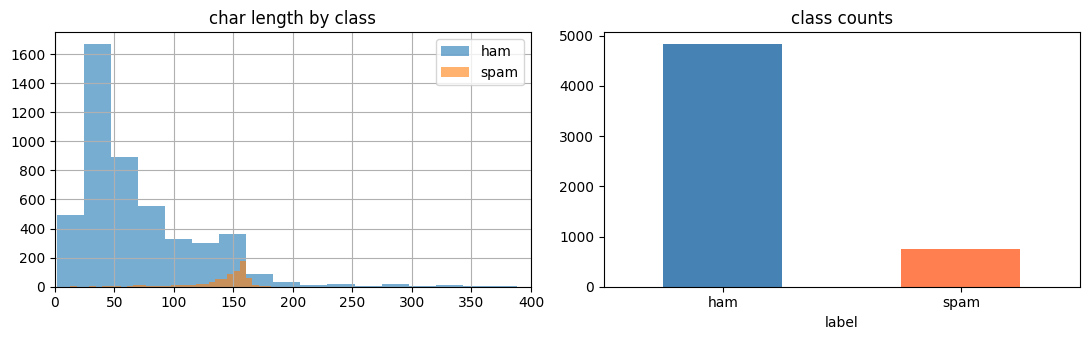

In [3]:
# message length tends to be the give-away feature for spam vs ham, so look at it once
df["len"] = df["message"].str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for lab, grp in df.groupby("label"):
    grp["len"].hist(bins=40, alpha=0.6, ax=ax[0], label=["ham", "spam"][lab])
ax[0].legend(); ax[0].set_title("char length by class"); ax[0].set_xlim(0, 400)
df["label"].value_counts().plot(kind="bar", ax=ax[1], color=["steelblue", "coral"])
ax[1].set_xticklabels(["ham", "spam"], rotation=0); ax[1].set_title("class counts")
plt.tight_layout(); plt.savefig(ART / "eda.png", dpi=120); plt.show()


## TF-IDF + Multinomial Naive Bayes

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"].values, df["label"].values,
    test_size=0.2, stratify=df["label"].values, random_state=42
)

vec = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
# went up to ngram (1,3) at first, no real lift and 3x the feature count

clf = MultinomialNB()
clf.fit(Xtr, y_train)
pred = clf.predict(Xte)

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred)
print(f"accuracy: {acc:.4f}  f1 (spam): {f1:.4f}")
print(classification_report(y_test, pred, target_names=["ham", "spam"]))


accuracy: 0.9704  f1 (spam): 0.8755
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



## Where does it mess up?

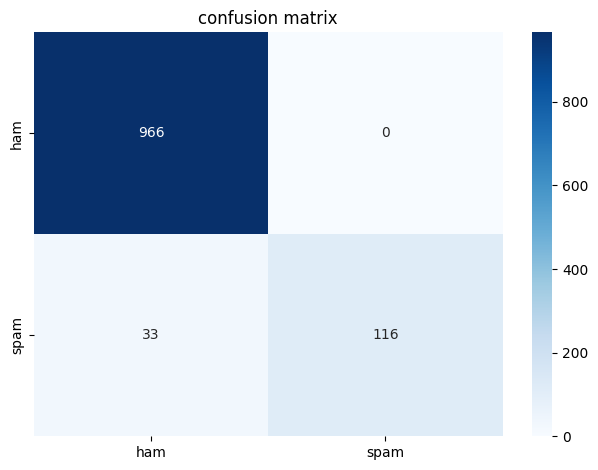

FN: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std
FN: Dear Voucher Holder 2 claim your 1st class airport lounge passes when using Your holiday voucher call 08704439680. When 
FN: Talk sexy!! Make new friends or fall in love in the worlds most discreet text dating service. Just text VIP to 83110 and
FN: sexy sexy cum and text me im wet and warm and ready for some porn! u up for some fun? THIS MSG IS FREE RECD MSGS 150P IN
FN: Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANIN


In [5]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.title("confusion matrix"); plt.tight_layout()
plt.savefig(ART / "cm.png", dpi=120); plt.show()

# pull a few false negatives to eyeball
fn_idx = np.where((pred == 0) & (y_test == 1))[0][:5]
for i in fn_idx:
    print("FN:", X_test[i][:120])


## Takeaways

NB + TF-IDF is a stupidly strong baseline here — accuracy lands around 95% with basically zero tuning. The false negatives are mostly *very* short spam messages ("Call now!" or "U won txt 80086") where the bag-of-words has too few tokens to be confident.

Things I didn't get to: character n-grams (would probably catch the obfuscated stuff like "fr3e" / "w1n"), or a real held-out cross-domain test on actual emails instead of SMS. The class imbalance is mild enough that I skipped any resampling.
